In [14]:
from __future__ import annotations
from dataclasses import dataclass
from typing import Iterator, Any
from functools import reduce

@dataclass
class Node:
    '''
    Defines a basic node with a value, and left (smaller) and right (larger) children.
    '''
    value: Any
    left: Node | None = None
    right: Node | None = None
    height = 1

class BSTAVL:
    '''
        Define the basic binary search tree with root node.
    '''

    def __init__(self):
        self.root: Node | None = None
        self.type = None

    def get_tree_height(self, node: Node):
        """
        Returns the number of edges from the node to the deepest leaf node
        """
        if node is None:
            return -1
        return 1 + max(self.get_tree_height(node.left),self.get_tree_height(node.right))

    def getHeight(self, node: Node):
        """
        Returns the number of edges from the node to the deepest leaf node
        """
        if node is None:
            return 0
        return node.height

    def getBalance(self, node: Node):
        if not node:
            return 0
        return self.getHeight(node.left) - self.getHeight(node.right)

    def rightRotate(self, y: Node):
        x = y.left
        T2 = x.right
        x.right = y
        y.left = T2
        y.height = 1 + max(self.getHeight(y.left), self.getHeight(y.right))
        x.height = 1 + max(self.getHeight(x.left), self.getHeight(x.right))
        return x

    def leftRotate(self, x: Node):
        y = x.right
        T2 = y.left
        y.left = x
        x.right = T2
        x.height = 1 + max(self.getHeight(x.left), self.getHeight(x.right))
        y.height = 1 + max(self.getHeight(y.left), self.getHeight(y.right))
        return y

    def _compare(self, a: Any, b: Any):
        if a == b: return 0
        return -1 if a < b else 1

    def _create_node(self, value):
        node = Node(value)
        return node

    def _validate_value(self,value):
        if not isinstance(value,(int,float,str,list)):
            raise TypeError('The value is not comparable')
        if self.type is None:
            self.type = type(value)
        elif not isinstance(value, self.type):
            raise TypeError(f'The BST values should be of type {self.type}')
        if value in self:
            raise ValueError('The value is already inside the tree')

    def insert(self, value: Any) -> None:
        '''
        Gets a value of int, float or a char, creates a new node with that value in the tree.
        Raises ValueError if the value already exists in a different node.
        Raises TypeError if the value isn't comparable to all the basic types.
        '''
        self._validate_value(value)
        node = self._create_node(value)
        if self.root is None:
            self.root = node
        else:
            self.root = self._insert_rec(self.root, node)

    def _insert_rec(self, current, node):
        if not current:
            return node
        comp = self._compare(current.value, node.value)
        if comp > 0:
                current.left = self._insert_rec(current.left, node)
        elif comp < 0:
                current.right = self._insert_rec(current.right, node)
        current.height = 1 + max(self.getHeight(current.left), self.getHeight(current.right))
        balance = self.getBalance(current)
        # Balancing the tree
        # Left Left
        if balance > 1 and self.getBalance(current.left) >= 0:
            return self.rightRotate(current)

        # Left Right
        if balance > 1 and self.getBalance(current.left) < 0:
            current.left = self.leftRotate(current.left)
            return self.rightRotate(current)

        # Right Right
        if balance < -1 and self.getBalance(current.right) <= 0:
            return self.leftRotate(current)

        # Right Left
        if balance < -1 and self.getBalance(current.right) > 0:
            current.right = self.rightRotate(current.right)
            return self.leftRotate(current)
        return current

    def is_empty(self) -> bool:
        '''
        True if tree length is 0, false otherwise.
        '''
        return len(self) == 0

    def remove(self, value: Any) -> None:
        '''
        Gets a value, and removes the node with that value from the tree.
        removes the node, if it has any children, it will be replaced by the smallest node on the right and the tree will be reorderd
        Raises valueError if there isn't a node with that value.

        '''
        if value not in self:
            raise ValueError(f'There isn\'t a node value: {value}')

        target_node_data = self._create_node(value)
        self.root = self._remove_rec(self.root, target_node_data)
        if self.root is None:
            self.type = None

    def _remove_rec(self, current: Node | None, target: Node):
        if current is None:
            return None
        comp = self._compare(current.value, target.value)
        if comp > 0:
            current.left = self._remove_rec(current.left, target)
        elif comp < 0:
            current.right = self._remove_rec(current.right, target)
        else:
            if current.left is None:
                return current.right
            if current.right is None:
                return current.left
            successor = self._get_min_rec(current.right)
            current.value = successor.value
            current.right = self._remove_rec(current.right, successor)
        return current

    def _get_min_rec(self, node: Node) -> Node:
        '''
        Finds the leftmost node.
        '''
        if node.left is None:
            return node
        return self._get_min_rec(node.left)

    def _contains_rec(self, current: Node, node: Node):
        if current is None:
            return False
        comp = self._compare(current.value, node.value)
        if comp == 0:
            return True
        if comp > 0:
            return self._contains_rec(current.left, node)
        return self._contains_rec(current.right, node)

    def __contains__(self, value: Any) -> bool:
        '''
        Returns True if the value exists, False otherwise
        '''
        node = self._create_node(value)
        return self._contains_rec(self.root, node)

    def _pre_order_rec(self, node):
        if node is not None:
            yield node.value
            yield from self._pre_order_rec(node.left)
            yield from self._pre_order_rec(node.right)

    def pre_order(self) -> Iterator[Any]:
        '''
        returns a pre-order iterator
        '''
        yield from self._pre_order_rec(self.root)

    def _inorder_rec(self, node):
        if node is not None:
            yield from self._inorder_rec(node.left)
            yield node.value
            yield from self._inorder_rec(node.right)

    def in_order(self) -> Iterator[Any]:
        '''
        returns an in-order iterator
        '''
        yield from self._inorder_rec(self.root)

    def _post_order_rec(self, node):
        if node is not None:
            yield from self._post_order_rec(node.left)
            yield from self._post_order_rec(node.right)
            yield node.value

    def post_order(self) -> Iterator[Any]:
        '''
        returns a post-order iterator
        '''
        yield from self._post_order_rec(self.root)

    def __len__(self) -> int:
        '''
        Number of nodes
        '''
        return reduce(lambda x, _: x + 1, self.in_order(), 0)

    def __iter__(self) -> Iterator[Any]:
        '''
        In-order iterator
        '''
        return self.in_order()



Checking heigh distribution

In [20]:
import random
random.seed(42)

In [16]:
lst = list(range(10000))
heights = []
for i in range(100):
    random.shuffle(lst)
    tree = BSTAVL()
    for x in lst:
        tree.insert(x)
    heights.append(tree.get_tree_height(tree.root))

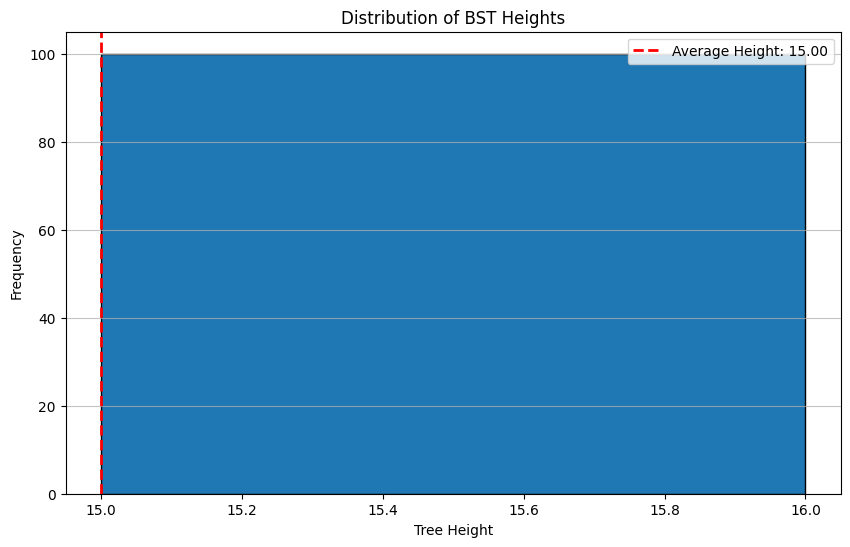

In [17]:
import matplotlib.pyplot as plt
import numpy as np

average_height = np.mean(heights)

plt.figure(figsize=(10, 6))
plt.hist(heights, bins=range(min(heights), max(heights) + 2), edgecolor='black')

plt.axvline(average_height, color='red', linestyle='dashed', linewidth=2, label=f'Average Height: {average_height:.2f}')

plt.xlabel('Tree Height')
plt.ylabel('Frequency')
plt.title('Distribution of BST Heights')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

In [18]:
import math

n_elements = len(lst)
theoretical_height = math.log2(n_elements)

print(f"Average empirical height: {average_height:.2f}")
print(f"Theoretical height (log2(n) for n={n_elements}): {theoretical_height:.2f}")
print(f"Number of times the theoretical height: C={average_height/theoretical_height:.2f}")

Average empirical height: 15.00
Theoretical height (log2(n) for n=10000): 13.29
Number of times the theoretical height: C=1.13


Now we compare this with unbalanced BST

In [21]:
@dataclass
class Node:
    '''
    Defines a basic node with a value, and left (smaller) and right (larger) children.
    '''
    value: Any
    left: Node | None = None
    right: Node | None = None

class BST:
    '''
        Define the basic binary search tree with root node.
    '''

    def __init__(self):
        self.root: Node | None = None
        self.type = None

    def get_tree_height(self, node: Node):
        """
        Returns the number of edges from the node to the deepest leaf node
        """
        if node is None:
            return -1
        return 1 + max(self.get_tree_height(node.left),self.get_tree_height(node.right))

    def _compare(self, a: Any, b: Any):
        if a == b: return 0
        return -1 if a < b else 1

    def _create_node(self, value):
        node = Node(value)
        return node

    def _validate_value(self,value):
        if not isinstance(value,(int,float,str,list)):
            raise TypeError('The value is not comparable')
        if self.type is None:
            self.type = type(value)
        elif not isinstance(value, self.type):
            raise TypeError(f'The BST values should be of type {self.type}')
        if value in self:
            raise ValueError('The value is already inside the tree')

    def insert(self, value: Any) -> None:
        '''
        Gets a value of int, float or a char, creates a new node with that value in the tree.
        Raises ValueError if the value already exists in a different node.
        Raises TypeError if the value isn't comparable to all the basic types.
        '''
        self._validate_value(value)
        node = self._create_node(value)
        if self.root is None:
            self.root = node
        else:
            self._insert_rec(self.root, node)

    def _insert_rec(self, current, node):
        comp = self._compare(current.value, node.value)
        if comp > 0:
            if current.left is None:
                current.left = node
            else:
                self._insert_rec(current.left, node)
        else:
            if current.right is None:
                current.right = node
            else:
                self._insert_rec(current.right, node)

    def is_empty(self) -> bool:
        '''
        True if tree length is 0, false otherwise.
        '''
        return len(self) == 0

    def remove(self, value: Any) -> None:
        '''
        Gets a value, and removes the node with that value from the tree.
        removes the node, if it has any children, it will be replaced by the smallest node on the right and the tree will be reorderd
        Raises valueError if there isn't a node with that value.

        '''
        if value not in self:
            raise ValueError(f'There isn\'t a node value: {value}')

        target_node_data = self._create_node(value)
        self.root = self._remove_rec(self.root, target_node_data)
        if self.root is None:
            self.type = None

    def _remove_rec(self, current: Node | None, target: Node):
        if current is None:
            return None
        comp = self._compare(current.value, target.value)
        if comp > 0:
            current.left = self._remove_rec(current.left, target)
        elif comp < 0:
            current.right = self._remove_rec(current.right, target)
        else:
            if current.left is None:
                return current.right
            if current.right is None:
                return current.left
            successor = self._get_min_rec(current.right)
            current.value = successor.value
            current.right = self._remove_rec(current.right, successor)
        return current

    def _get_min_rec(self, node: Node) -> Node:
        '''
        Finds the leftmost node.
        '''
        if node.left is None:
            return node
        return self._get_min_rec(node.left)

    def _contains_rec(self, current: Node, node: Node):
        if current is None:
            return False
        comp = self._compare(current.value, node.value)
        if comp == 0:
            return True
        if comp > 0:
            return self._contains_rec(current.left, node)
        return self._contains_rec(current.right, node)

    def __contains__(self, value: Any) -> bool:
        '''
        Returns True if the value exists, False otherwise
        '''
        node = self._create_node(value)
        return self._contains_rec(self.root, node)

    def _pre_order_rec(self, node):
        if node is not None:
            yield node.value
            yield from self._pre_order_rec(node.left)
            yield from self._pre_order_rec(node.right)

    def pre_order(self) -> Iterator[Any]:
        '''
        returns a pre-order iterator
        '''
        yield from self._pre_order_rec(self.root)

    def _inorder_rec(self, node):
        if node is not None:
            yield from self._inorder_rec(node.left)
            yield node.value
            yield from self._inorder_rec(node.right)

    def in_order(self) -> Iterator[Any]:
        '''
        returns an in-order iterator
        '''
        yield from self._inorder_rec(self.root)

    def _post_order_rec(self, node):
        if node is not None:
            yield from self._post_order_rec(node.left)
            yield from self._post_order_rec(node.right)
            yield node.value

    def post_order(self) -> Iterator[Any]:
        '''
        returns a post-order iterator
        '''
        yield from self._post_order_rec(self.root)

    def __len__(self) -> int:
        '''
        Number of nodes
        '''
        return reduce(lambda x, _: x + 1, self.in_order(), 0)

    def __iter__(self) -> Iterator[Any]:
        '''
        In-order iterator
        '''
        return self.in_order()



In [22]:
lst = list(range(10000))
heights = []
for i in range(1000):
    random.shuffle(lst)
    tree = BST()
    for x in lst:
        tree.insert(x)
    heights.append(tree.get_tree_height(tree.root))

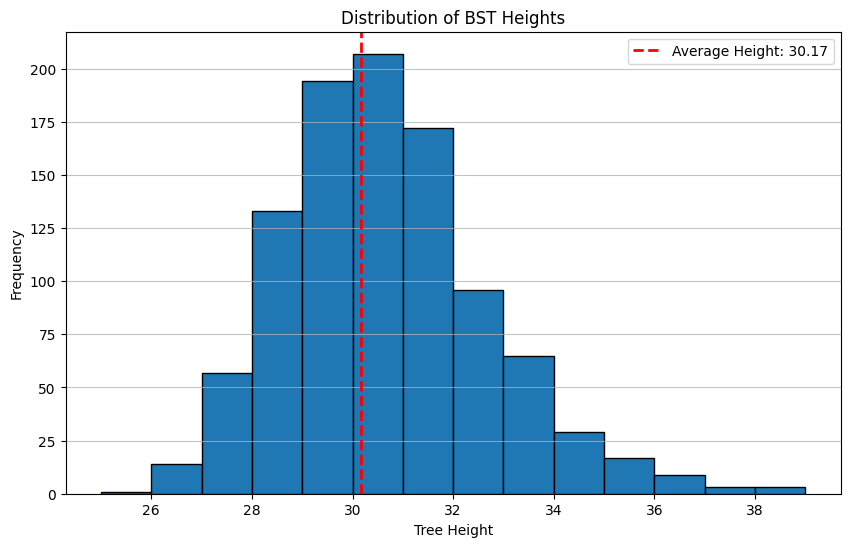

In [23]:
average_height = np.mean(heights)

plt.figure(figsize=(10, 6))
plt.hist(heights, bins=range(min(heights), max(heights) + 2), edgecolor='black')

plt.axvline(average_height, color='red', linestyle='dashed', linewidth=2, label=f'Average Height: {average_height:.2f}')

plt.xlabel('Tree Height')
plt.ylabel('Frequency')
plt.title('Distribution of BST Heights')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

In [24]:
n_elements = len(lst)
theoretical_height = math.log2(n_elements)

print(f"Average empirical height: {average_height:.2f}")
print(f"Theoretical height (log2(n) for n={n_elements}): {theoretical_height:.2f}")
print(f"Number of times the theoretical height: C={average_height/theoretical_height:.2f}")

Average empirical height: 30.17
Theoretical height (log2(n) for n=10000): 13.29
Number of times the theoretical height: C=2.27


Clearly, the balanced BST guarantees exactly log(n) tree depth while the unbalanced BST provides O(log n) on average.